# Medical Insurance Cost Prediction — CA-4 (Supervised Machine Learning)

**Problem type:** Regression  **Target:** `charges` (annual medical insurance cost, USD)
**Dataset:** Medical Cost Personal Dataset — Kaggle (`mirichoi0218/insurance`), 1,338 records, 7 columns

**Name:** Harshit Divekar  **Programme:** B.Tech CSE (AI/ML), Symbiosis Institute of Technology

| Week | Content in this notebook |
|---|---|
| Week 1 | Problem understanding, data description, EDA (missing values, outliers, distributions, correlation), encoding, 70/30 split |
| Week 1 | Baseline models — Linear Regression, Decision Tree, KNN — evaluated with MAE, RMSE, R² |
| Week 2 | Random Forest, Gradient Boosting, XGBoost, GridSearchCV tuning, 5-fold cross-validation, residual analysis, feature importance |
| Week 4 | Final model selection, feature-importance explanation, business insights, limitations, future work, deployment insight |

## 1. Problem Understanding

Health insurers must price policies so that premiums cover expected medical costs. If the expected cost of a
customer can be estimated from a few attributes known at sign-up (age, BMI, smoking status, etc.), the insurer can
price risk fairly, plan reserves and design targeted wellness programmes.

**Goal:** learn a function *f(age, sex, bmi, children, smoker, region) → charges* that predicts the yearly
medical cost billed by the insurer for an individual, and explain which factors drive cost.

In [1]:
import warnings, json, os
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
import joblib

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
os.makedirs('figures', exist_ok=True)
RANDOM_STATE = 42
RESULTS = {}

def savefig(name):
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 2. Load the Dataset
Download `insurance.csv` from https://www.kaggle.com/datasets/mirichoi0218/insurance and place it next to this notebook.

In [2]:
df = pd.read_csv('insurance.csv')
print('Shape:', df.shape)
df.head()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. Dataset Description — size, feature types, target

In [3]:
print(f'Rows: {df.shape[0]}   Columns: {df.shape[1]}')
df.info()

Rows: 1338   Columns: 7
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [4]:
feature_types = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'kind': ['Numerical (discrete)', 'Categorical (binary)', 'Numerical (continuous)',
             'Numerical (discrete)', 'Categorical (binary)', 'Categorical (4 levels)', 'TARGET — numerical (continuous)'],
    'unique_values': df.nunique()
})
feature_types

,dtype,kind,unique_values
age,int64,Numerical (discrete),47
sex,str,Categorical (binary),2
bmi,float64,Numerical (continuous),548
children,int64,Numerical (discrete),6
smoker,str,Categorical (binary),2
region,str,Categorical (4 levels),4
charges,float64,TARGET — numerical (continuous),1337


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.21,14.05,18.00,27.00,39.00,51.00,64.00
bmi,1338.0,30.66,6.10,15.96,26.30,30.40,34.69,53.13
children,1338.0,1.09,1.21,0.00,0.00,1.00,2.00,5.00
charges,1338.0,13270.42,12110.01,1121.87,4740.29,9382.03,16639.91,63770.43


In [6]:
for col in ['sex', 'smoker', 'region']:
    print(df[col].value_counts(), '\n')

sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64 



## 4. Missing Value & Duplicate Analysis

In [7]:
missing = df.isnull().sum()
print('Missing values per column:\n', missing)
print('\nTotal missing:', missing.sum())
dups = df.duplicated().sum()
print('Duplicate rows:', dups)
display(df[df.duplicated(keep=False)])

Missing values per column:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total missing: 0
Duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [8]:
# Remove the exact duplicate row so it cannot appear in both train and test
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)
RESULTS['n_rows'] = int(df.shape[0]); RESULTS['n_duplicates_removed'] = int(dups)

Shape after removing duplicates: (1337, 7)


## 5. Outlier Detection (IQR method + boxplots)

In [9]:
num_cols = ['age', 'bmi', 'children', 'charges']
outlier_summary = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[c] < lo) | (df[c] > hi)).sum()
    outlier_summary.append([c, round(lo, 2), round(hi, 2), int(n), round(100 * n / len(df), 2)])
outlier_df = pd.DataFrame(outlier_summary, columns=['feature', 'lower_fence', 'upper_fence', 'n_outliers', '% rows'])
RESULTS['outliers'] = outlier_df.to_dict(orient='records')
outlier_df

,feature,lower_fence,upper_fence,n_outliers,% rows
0,age,-9.00,87.00,0,0.00
1,bmi,13.67,47.32,9,0.67
2,children,-3.00,5.00,0,0.00
3,charges,-13120.72,34524.78,139,10.40


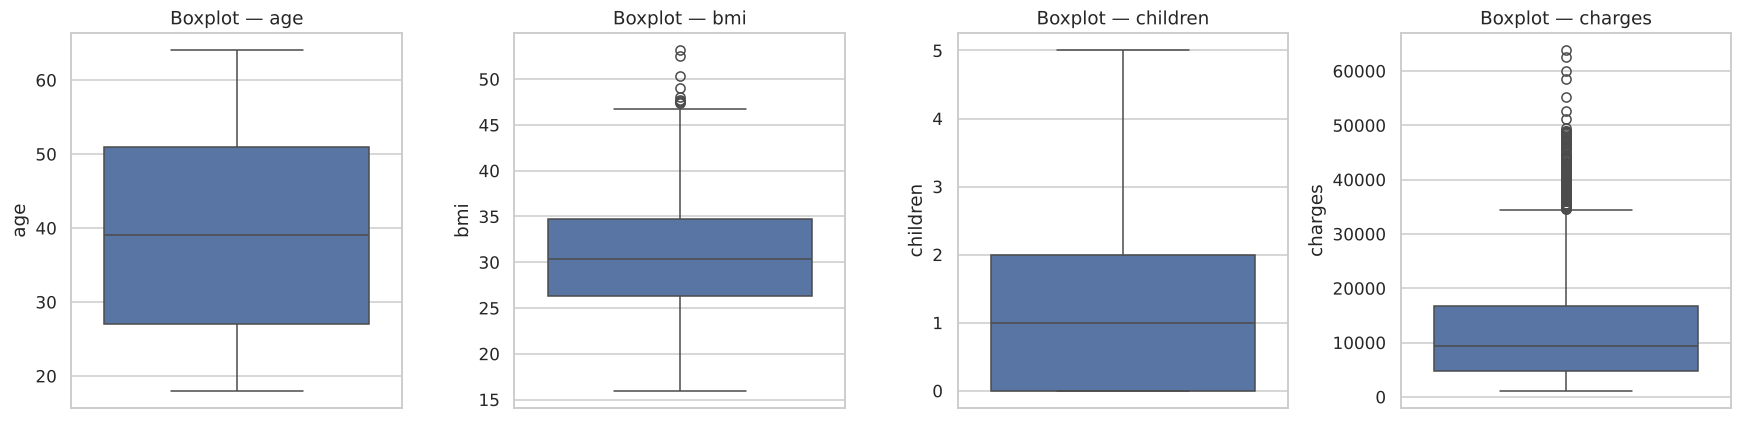

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color='#4C72B0')
    ax.set_title(f'Boxplot — {c}')
savefig('01_boxplots')

In [11]:
# Are the high-charge 'outliers' errors or real? Check smoker share among them.
q3 = df.charges.quantile(0.75); iqr = q3 - df.charges.quantile(0.25)
high = df[df.charges > q3 + 1.5 * iqr]
print('Smoker share among charge outliers: {:.1%}'.format((high.smoker == 'yes').mean()))
print('Smoker share overall:               {:.1%}'.format((df.smoker == 'yes').mean()))
RESULTS['smoker_share_outliers'] = float((high.smoker == 'yes').mean())
RESULTS['smoker_share_overall'] = float((df.smoker == 'yes').mean())

Smoker share among charge outliers: 97.8%
Smoker share overall:               20.5%


**Decision:** The high `charges` values are dominated by smokers — they are genuine high-cost customers, not
data-entry errors. Removing them would delete exactly the cases the insurer most needs to price, so **outliers are kept**.
The few BMI outliers (BMI > ~47) are medically plausible (severe obesity) and are also kept.

## 6. Distribution Analysis

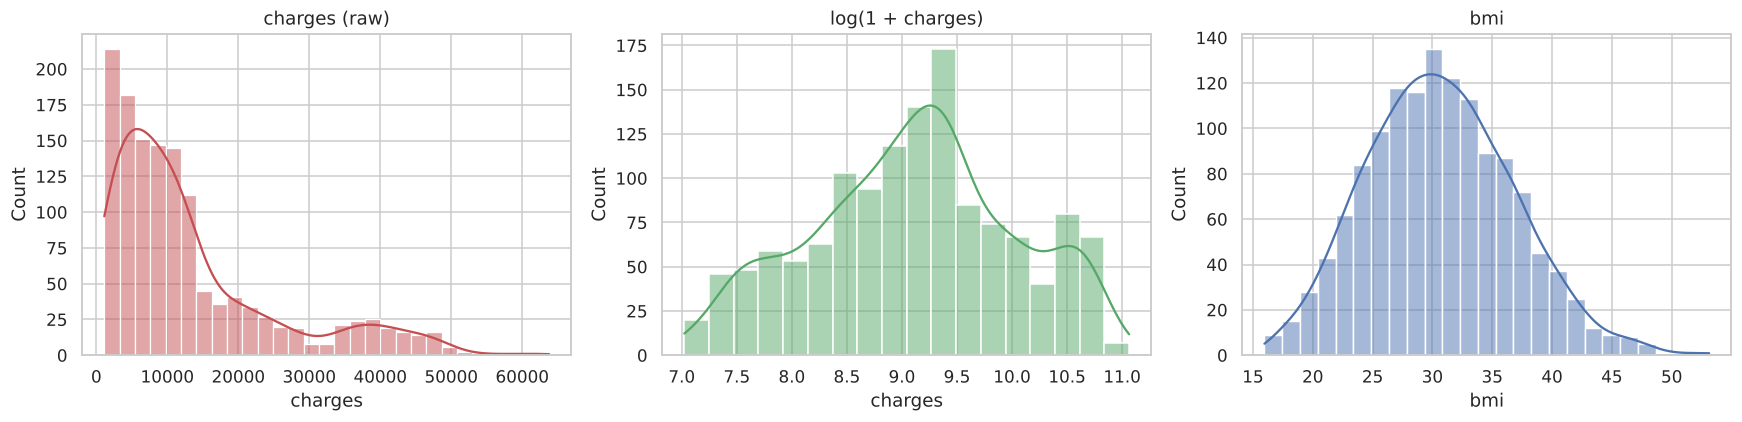

Skewness of charges: 1.52
Skewness of log(charges): -0.09


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df.charges, kde=True, ax=axes[0], color='#C44E52'); axes[0].set_title('charges (raw)')
sns.histplot(np.log1p(df.charges), kde=True, ax=axes[1], color='#55A868'); axes[1].set_title('log(1 + charges)')
sns.histplot(df.bmi, kde=True, ax=axes[2], color='#4C72B0'); axes[2].set_title('bmi')
savefig('02_target_distribution')
print('Skewness of charges: {:.2f}'.format(df.charges.skew()))
print('Skewness of log(charges): {:.2f}'.format(np.log1p(df.charges).skew()))
RESULTS['skew_charges'] = float(df.charges.skew())

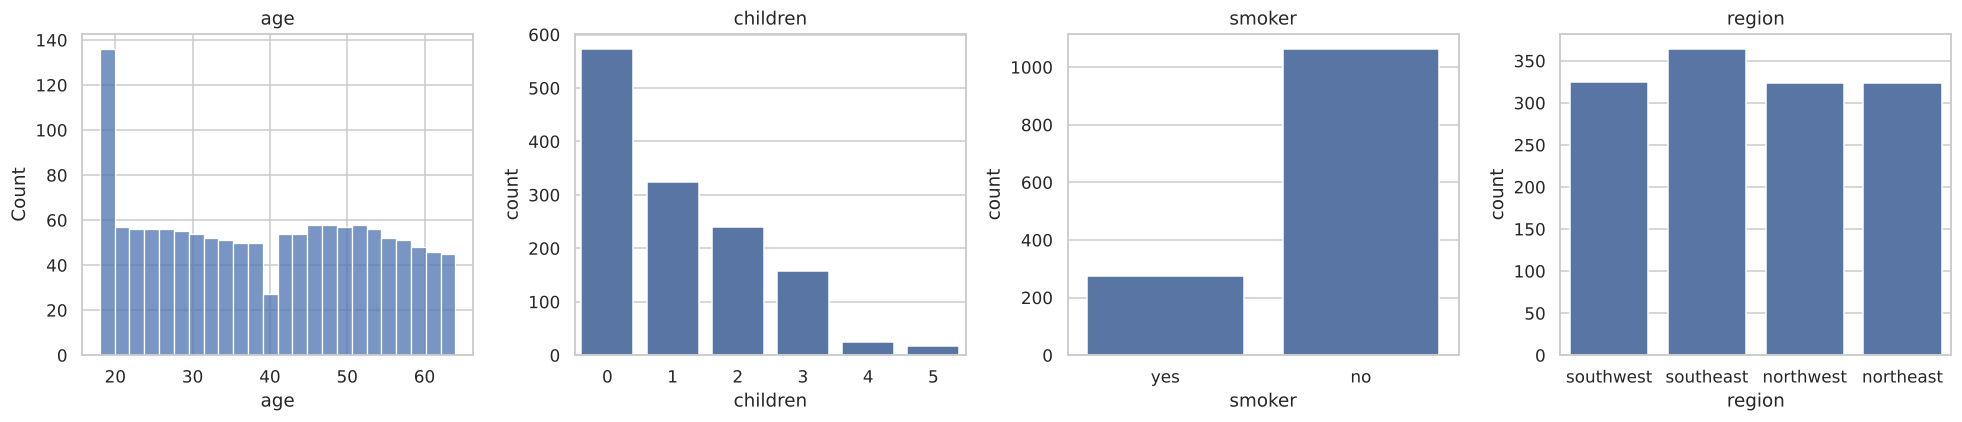

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.histplot(df.age, bins=24, ax=axes[0]); axes[0].set_title('age')
sns.countplot(x='children', data=df, ax=axes[1]); axes[1].set_title('children')
sns.countplot(x='smoker', data=df, ax=axes[2]); axes[2].set_title('smoker')
sns.countplot(x='region', data=df, ax=axes[3]); axes[3].set_title('region')
savefig('03_feature_distributions')

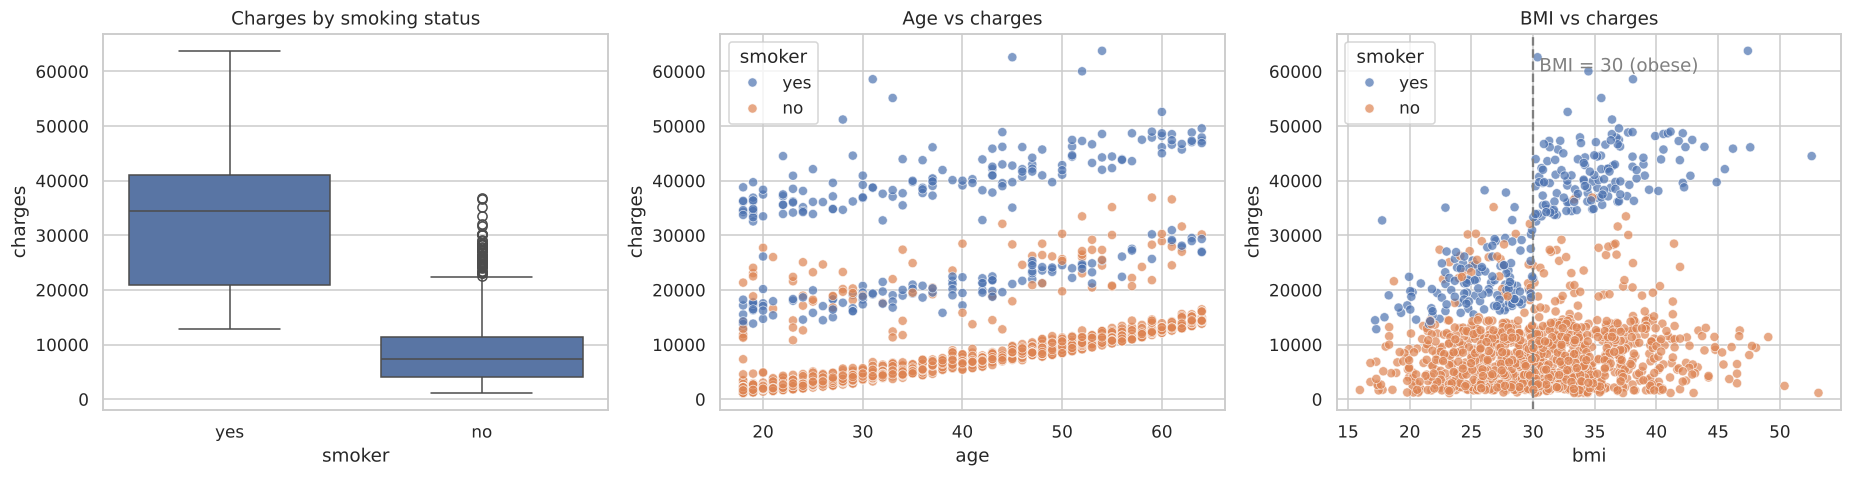

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(x='smoker', y='charges', data=df, ax=axes[0]); axes[0].set_title('Charges by smoking status')
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, ax=axes[1], alpha=.7); axes[1].set_title('Age vs charges')
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, ax=axes[2], alpha=.7); axes[2].set_title('BMI vs charges')
axes[2].axvline(30, ls='--', c='grey'); axes[2].text(30.5, 60000, 'BMI = 30 (obese)', color='grey')
savefig('04_bivariate')

In [15]:
grp = df.groupby('smoker').charges.agg(['mean', 'median', 'count']).round(0)
print(grp)
RESULTS['mean_charge_smoker'] = float(grp.loc['yes', 'mean']); RESULTS['mean_charge_nonsmoker'] = float(grp.loc['no', 'mean'])
seg = df.assign(obese=df.bmi >= 30).groupby(['smoker', 'obese']).charges.mean().round(0)
print('\nMean charges by smoker x obese (BMI>=30):\n', seg)
RESULTS['seg_means'] = {f'{k[0]}_{"obese" if k[1] else "notobese"}': float(v) for k, v in seg.items()}
print('\nMean charges by region:\n', df.groupby('region').charges.mean().round(0))
print('\nMean charges by sex:\n', df.groupby('sex').charges.mean().round(0))

           mean   median  count
smoker                         
no       8441.0   7346.0   1063
yes     32050.0  34456.0    274

Mean charges by smoker x obese (BMI>=30):
 smoker  obese
no      False     7977.0
        True      8856.0
yes     False    21363.0
        True     41558.0
Name: charges, dtype: float64

Mean charges by region:
 region
northeast    13406.0
northwest    12451.0
southeast    14735.0
southwest    12347.0
Name: charges, dtype: float64

Mean charges by sex:
 sex
female    12570.0
male      13975.0
Name: charges, dtype: float64


## 7. Feature Encoding

- `sex`, `smoker` → binary 0/1 dummies
- `region` → one-hot encoding (`drop_first=True` to avoid the dummy-variable trap for Linear Regression)
- Numerical features left as they are; scaling is applied **inside a pipeline** only for KNN (distance-based), so it is fitted on training data only (no leakage).

In [16]:
df_enc = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)
df_enc.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


## 8. Correlation Analysis

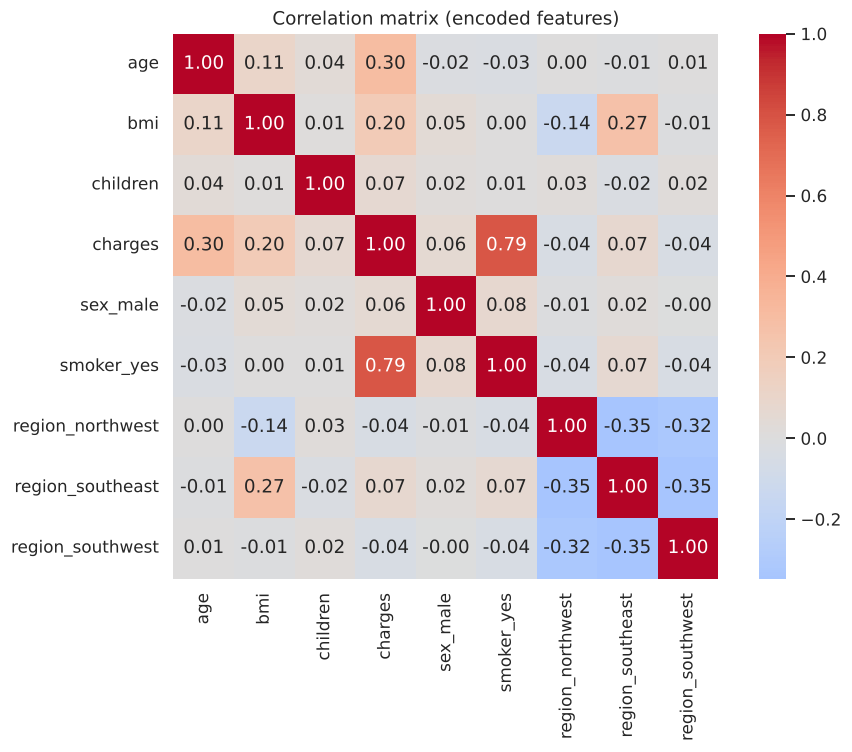

smoker_yes          0.787234
age                 0.298308
bmi                 0.198401
region_southeast    0.073578
children            0.067389
sex_male            0.058044
region_southwest   -0.043637
region_northwest   -0.038695
Name: charges, dtype: float64

In [17]:
plt.figure(figsize=(9, 7))
corr = df_enc.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation matrix (encoded features)')
savefig('05_correlation')
target_corr = corr['charges'].drop('charges').sort_values(key=abs, ascending=False)
RESULTS['target_corr'] = target_corr.round(3).to_dict()
target_corr

**Observations:** `smoker_yes` has by far the strongest correlation with charges (~0.79), followed by `age` (~0.30)
and `bmi` (~0.20). Sex, region and children are weakly related. Features are not strongly correlated with each other,
so multicollinearity is not a concern.

## 9. Train / Test Split (70% / 30%)

In [18]:
X = df_enc.drop(columns='charges')
y = df_enc['charges']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)
RESULTS['n_train'] = int(len(X_train)); RESULTS['n_test'] = int(len(X_test))
FEATURES = list(X.columns)

Train: (935, 8)  Test: (402, 8)


# WEEK 1 — Baseline Modeling

In [19]:
def evaluate(name, model, X_tr=None, X_te=None):
    X_tr = X_train if X_tr is None else X_tr
    X_te = X_test if X_te is None else X_te
    pred_tr, pred_te = model.predict(X_tr), model.predict(X_te)
    return {'Model': name,
            'Train R2': r2_score(y_train, pred_tr),
            'MAE': mean_absolute_error(y_test, pred_te),
            'RMSE': np.sqrt(mean_squared_error(y_test, pred_te)),
            'R2': r2_score(y_test, pred_te)}

baselines = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'KNN (k=5, scaled)': Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=5))]),
}
rows = []
for name, m in baselines.items():
    m.fit(X_train, y_train)
    rows.append(evaluate(name, m))
baseline_df = pd.DataFrame(rows).set_index('Model')
RESULTS['baseline'] = baseline_df.round(4).reset_index().to_dict(orient='records')
baseline_df.style.format({'Train R2': '{:.3f}', 'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'R2': '{:.3f}'})

,Train R2,MAE,RMSE,R2
Model,,,,
Linear Regression,0.736,"4,182","6,240",0.772
Decision Tree,1.000,"2,885","6,204",0.775
"KNN (k=5, scaled)",0.855,"3,549","5,731",0.808


In [20]:
lr = baselines['Linear Regression']
coef = pd.Series(lr.coef_, index=FEATURES).sort_values()
print('Intercept: {:,.0f}'.format(lr.intercept_))
RESULTS['lr_coef'] = coef.round(1).to_dict()
coef.round(1)

Intercept: -11,517


region_southeast     -936.1
region_southwest     -765.6
region_northwest     -465.7
sex_male             -111.9
age                   251.2
bmi                   328.4
children              522.2
smoker_yes          22874.4
dtype: float64

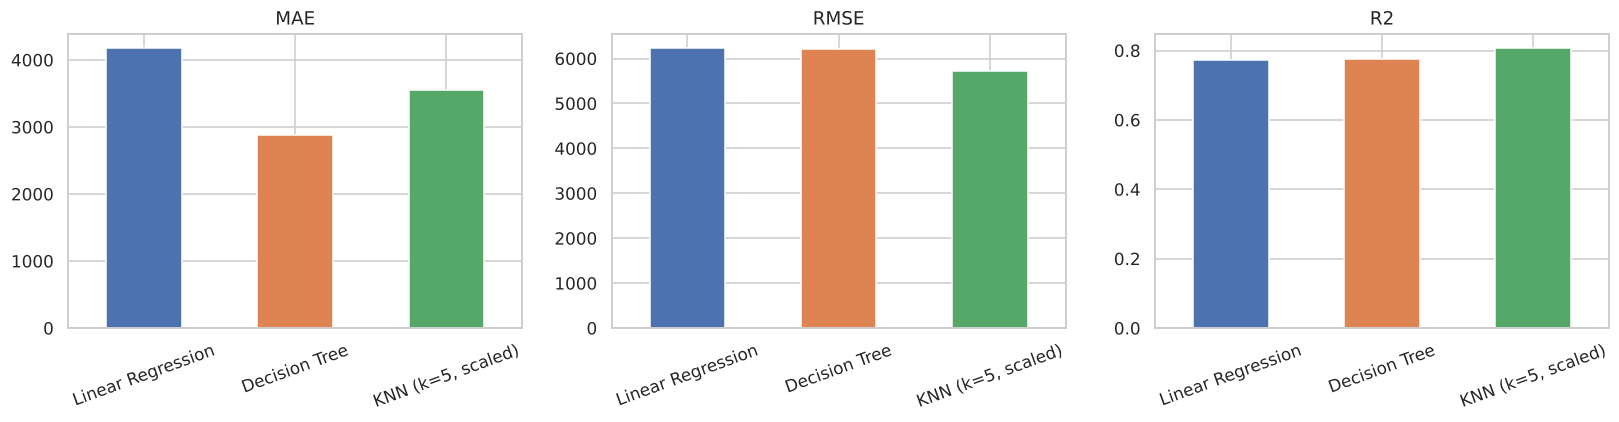

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics = ['MAE', 'RMSE', 'R2']
for ax, met in zip(axes, metrics):
    baseline_df[met].plot.bar(ax=ax, color=['#4C72B0', '#DD8452', '#55A868'])
    ax.set_title(met); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
savefig('06_baseline_comparison')

### Interpretation (baseline)
- **Linear Regression** (R² ≈ 0.77, RMSE ≈ $6,240) has the highest MAE of the three. Its coefficients are
  interpretable — being a smoker adds about $22.9k per year, each year of age about $250 and each BMI unit about $330 —
  but a straight-line model cannot capture the *interaction* seen in EDA (obese smokers cost much more than smoking and
  obesity would add separately), so its errors are large across the board.
- **Decision Tree (unpruned)** has the lowest MAE (≈ $2,885) because it predicts typical non-smokers very closely, but
  it fits the training data perfectly (Train R² = 1.0) and its RMSE is no better than Linear Regression — a few big
  mistakes dominate. This is classic **overfitting**; its 5-fold CV R² (≈ 0.68) is the worst of all models.
- **KNN (k = 5, on scaled features)** gives the best baseline R² (≈ 0.81) and RMSE (≈ $5,731): neighbours with the same
  smoking status and similar age/BMI have similar costs. It still trails the ensembles and gives no interpretability.

None of the baselines handles the smoker × BMI interaction and the overfitting problem at the same time. That
motivates ensemble tree models, which learn non-linear interactions while controlling variance.

# WEEK 2 — Advanced Modeling & Optimization

### 5-fold cross-validation on the training set (default hyper-parameters)

In [22]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'KNN (k=5, scaled)': Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor())]),
    'Random Forest': RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=0),
}
cv_rows = []
for name, m in candidates.items():
    r2 = cross_val_score(m, X_train, y_train, cv=kf, scoring='r2')
    rmse = -cross_val_score(m, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    cv_rows.append({'Model': name, 'CV R2 mean': r2.mean(), 'CV R2 std': r2.std(), 'CV RMSE mean': rmse.mean()})
cv_df = pd.DataFrame(cv_rows).set_index('Model').sort_values('CV R2 mean', ascending=False)
RESULTS['cv_default'] = cv_df.round(4).reset_index().to_dict(orient='records')
cv_df.style.format({'CV R2 mean': '{:.3f}', 'CV R2 std': '{:.3f}', 'CV RMSE mean': '{:,.0f}'})

,CV R2 mean,CV R2 std,CV RMSE mean
Model,,,
Gradient Boosting,0.834,0.057,"4,597"
Random Forest,0.816,0.058,"4,874"
XGBoost,0.785,0.062,"5,274"
"KNN (k=5, scaled)",0.769,0.054,"5,501"
Linear Regression,0.723,0.064,"6,024"
Decision Tree,0.682,0.047,"6,502"


### Hyper-parameter tuning with GridSearchCV (5-fold, scoring = RMSE)

In [23]:
grids = {
    'Decision Tree (tuned)': (DecisionTreeRegressor(random_state=RANDOM_STATE),
        {'max_depth': [3, 4, 5, 6, 8], 'min_samples_leaf': [1, 5, 10, 20]}),
    'KNN (tuned)': (Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor())]),
        {'knn__n_neighbors': [3, 5, 7, 9, 11, 15], 'knn__weights': ['uniform', 'distance']}),
    'Random Forest (tuned)': (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        {'n_estimators': [200, 400], 'max_depth': [4, 6, 8, None], 'min_samples_leaf': [1, 5, 10],
         'max_features': [1.0, 0.6]}),
    'Gradient Boosting (tuned)': (GradientBoostingRegressor(random_state=RANDOM_STATE),
        {'n_estimators': [100, 200, 300], 'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [2, 3, 4],
         'subsample': [0.8, 1.0]}),
    'XGBoost (tuned)': (XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=0),
        {'n_estimators': [200, 400], 'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [2, 3, 4],
         'subsample': [0.8, 1.0], 'colsample_bytree': [0.8, 1.0]}),
}
tuned, best_params, tuned_cv = {}, {}, {}
for name, (est, grid) in grids.items():
    gs = GridSearchCV(est, grid, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    best_params[name] = gs.best_params_
    tuned_cv[name] = -gs.best_score_
    print(f'{name:28s} best CV RMSE = {-gs.best_score_:,.0f}   params = {gs.best_params_}')
RESULTS['best_params'] = {k: {p: (v if not isinstance(v, (np.floating, np.integer)) else v.item()) for p, v in d.items()} for k, d in best_params.items()}

Decision Tree (tuned)        best CV RMSE = 4,556   params = {'max_depth': 4, 'min_samples_leaf': 10}


KNN (tuned)                  best CV RMSE = 5,427   params = {'knn__n_neighbors': 5, 'knn__weights': 'distance'}


Random Forest (tuned)        best CV RMSE = 4,389   params = {'max_depth': 4, 'max_features': 1.0, 'min_samples_leaf': 5, 'n_estimators': 400}


Gradient Boosting (tuned)    best CV RMSE = 4,429   params = {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200, 'subsample': 0.8}


XGBoost (tuned)              best CV RMSE = 4,399   params = {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}


### Tuned model performance on the held-out 30% test set

In [24]:
all_models = {'Linear Regression': baselines['Linear Regression'],
              'Decision Tree (default)': baselines['Decision Tree'],
              'KNN (default)': baselines['KNN (k=5, scaled)'], **tuned}
final_rows = []
for name, m in all_models.items():
    r = evaluate(name, m)
    r['CV R2 (5-fold)'] = cross_val_score(m, X_train, y_train, cv=kf, scoring='r2').mean()
    final_rows.append(r)
final_df = pd.DataFrame(final_rows).set_index('Model').sort_values('RMSE')
RESULTS['final_table'] = final_df.round(4).reset_index().to_dict(orient='records')
final_df.style.format({'Train R2': '{:.3f}', 'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'R2': '{:.3f}', 'CV R2 (5-fold)': '{:.3f}'})

,Train R2,MAE,RMSE,R2,CV R2 (5-fold)
Model,,,,,
XGBoost (tuned),0.881,"2,566","4,622",0.875,0.846
Random Forest (tuned),0.870,"2,577","4,636",0.874,0.847
Gradient Boosting (tuned),0.870,"2,625","4,698",0.871,0.845
Decision Tree (tuned),0.863,"2,720","4,779",0.867,0.836
KNN (default),0.855,"3,549","5,731",0.808,0.769
KNN (tuned),1.000,"3,424","5,743",0.807,0.775
Decision Tree (default),1.000,"2,885","6,204",0.775,0.682
Linear Regression,0.736,"4,182","6,240",0.772,0.723


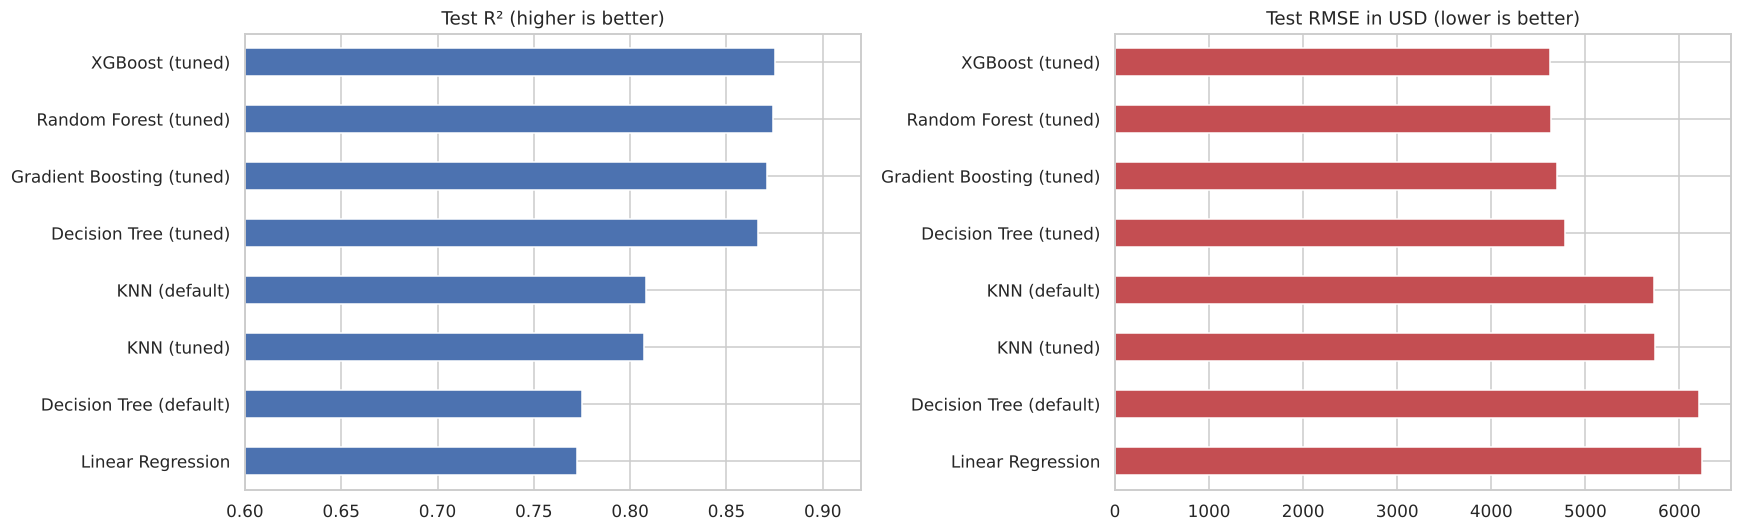

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = final_df.sort_values('R2').index
final_df.loc[order, 'R2'].plot.barh(ax=axes[0], color='#4C72B0'); axes[0].set_title('Test R² (higher is better)'); axes[0].set_xlim(0.6, 0.92)
final_df.loc[order, 'RMSE'].plot.barh(ax=axes[1], color='#C44E52'); axes[1].set_title('Test RMSE in USD (lower is better)')
for ax in axes: ax.set_ylabel('')
savefig('07_all_models_comparison')

In [26]:
best_name = final_df['RMSE'].idxmin()
best_model = all_models[best_name]
print('Best model on test RMSE:', best_name)
print(final_df.loc[best_name].round(3))
RESULTS['best_model'] = best_name

Best model on test RMSE: XGBoost (tuned)
Train R2             0.881
MAE               2566.017
RMSE              4621.664
R2                   0.875
CV R2 (5-fold)       0.846
Name: XGBoost (tuned), dtype: float64


### Residual analysis

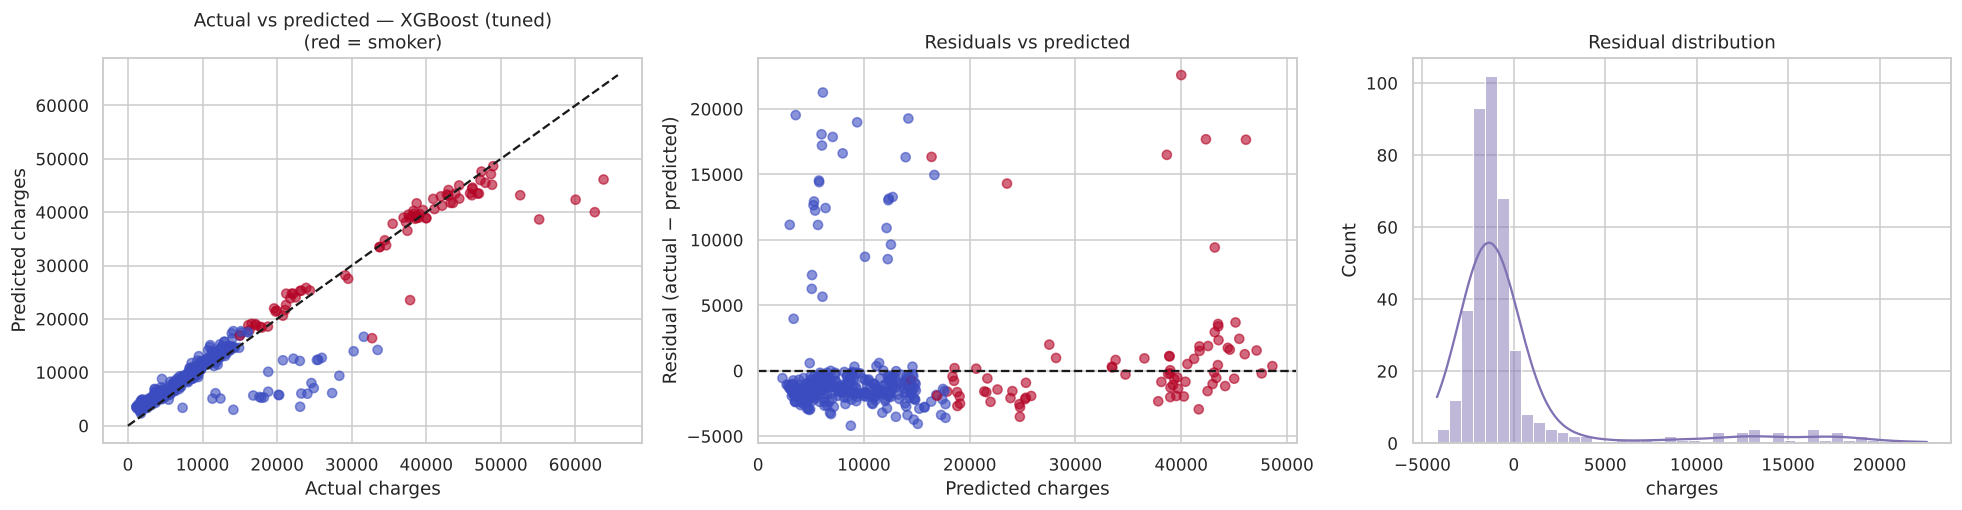

Mean residual: 113  Median residual: -1,214
Share of test rows with |residual| < $2,000: 69.9%
Share of rows under-predicted by > $5,000: 8.7%


In [27]:
pred = best_model.predict(X_test)
resid = y_test - pred
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].scatter(y_test, pred, alpha=.6, c=X_test['smoker_yes'], cmap='coolwarm')
lim = [0, max(y_test.max(), pred.max()) * 1.03]
axes[0].plot(lim, lim, 'k--'); axes[0].set_xlabel('Actual charges'); axes[0].set_ylabel('Predicted charges')
axes[0].set_title(f'Actual vs predicted — {best_name}\n(red = smoker)')
axes[1].scatter(pred, resid, alpha=.6, c=X_test['smoker_yes'], cmap='coolwarm'); axes[1].axhline(0, c='k', ls='--')
axes[1].set_xlabel('Predicted charges'); axes[1].set_ylabel('Residual (actual − predicted)'); axes[1].set_title('Residuals vs predicted')
sns.histplot(resid, kde=True, ax=axes[2], color='#8172B3'); axes[2].set_title('Residual distribution')
savefig('08_residuals_best')
print('Mean residual: {:,.0f}  Median residual: {:,.0f}'.format(resid.mean(), resid.median()))
print('Share of test rows with |residual| < $2,000: {:.1%}'.format((resid.abs() < 2000).mean()))
print('Share of rows under-predicted by > $5,000: {:.1%}'.format((resid > 5000).mean()))
RESULTS['resid'] = {'mean': float(resid.mean()), 'median': float(resid.median()),
                    'within_2000': float((resid.abs() < 2000).mean()), 'under_5000': float((resid > 5000).mean())}

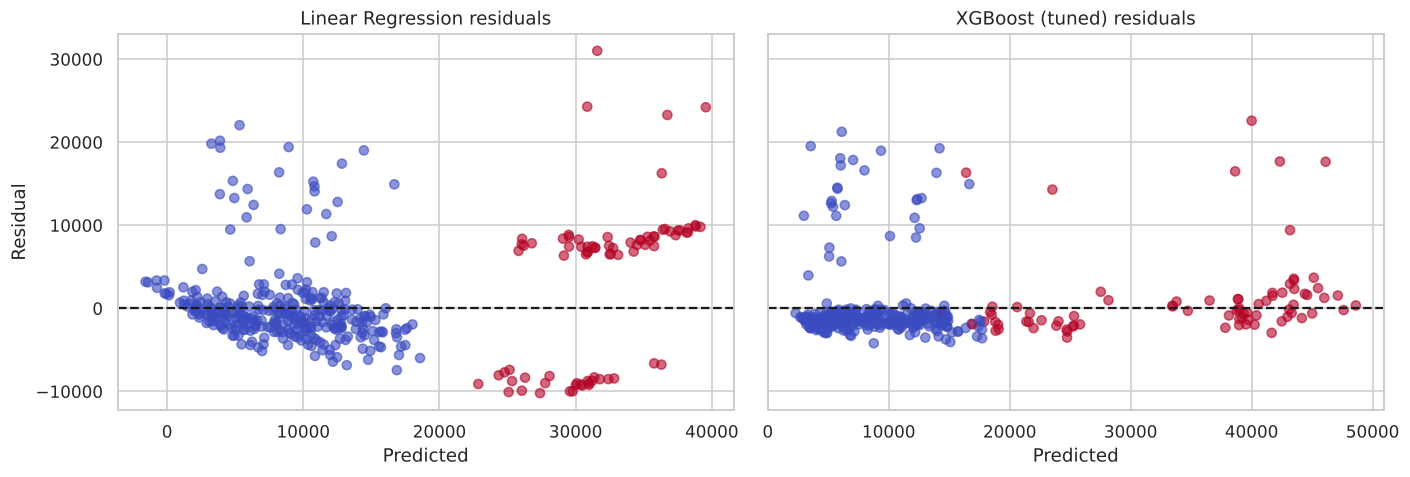

In [28]:
# Compare with linear-regression residuals to show why the ensemble is better
lr_resid = y_test - lr.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].scatter(lr.predict(X_test), lr_resid, alpha=.6, c=X_test['smoker_yes'], cmap='coolwarm'); axes[0].axhline(0, c='k', ls='--')
axes[0].set_title('Linear Regression residuals'); axes[0].set_xlabel('Predicted')
axes[1].scatter(pred, resid, alpha=.6, c=X_test['smoker_yes'], cmap='coolwarm'); axes[1].axhline(0, c='k', ls='--')
axes[1].set_title(f'{best_name} residuals'); axes[1].set_xlabel('Predicted')
axes[0].set_ylabel('Residual')
savefig('09_residuals_lr_vs_best')

**Residual interpretation:** Linear Regression shows clear structured bands (it systematically under-predicts obese
smokers and over-predicts non-obese smokers). The tuned ensemble removes most of that structure: most residuals sit
in a tight band around zero. What remains is a set of **positive residuals** — people whose actual charges are well
above prediction. These are mostly non-smokers with unexpectedly high bills, probably caused by health events
(accidents, chronic disease) that the six features cannot see. This is irreducible error given the available data.

### Feature importance

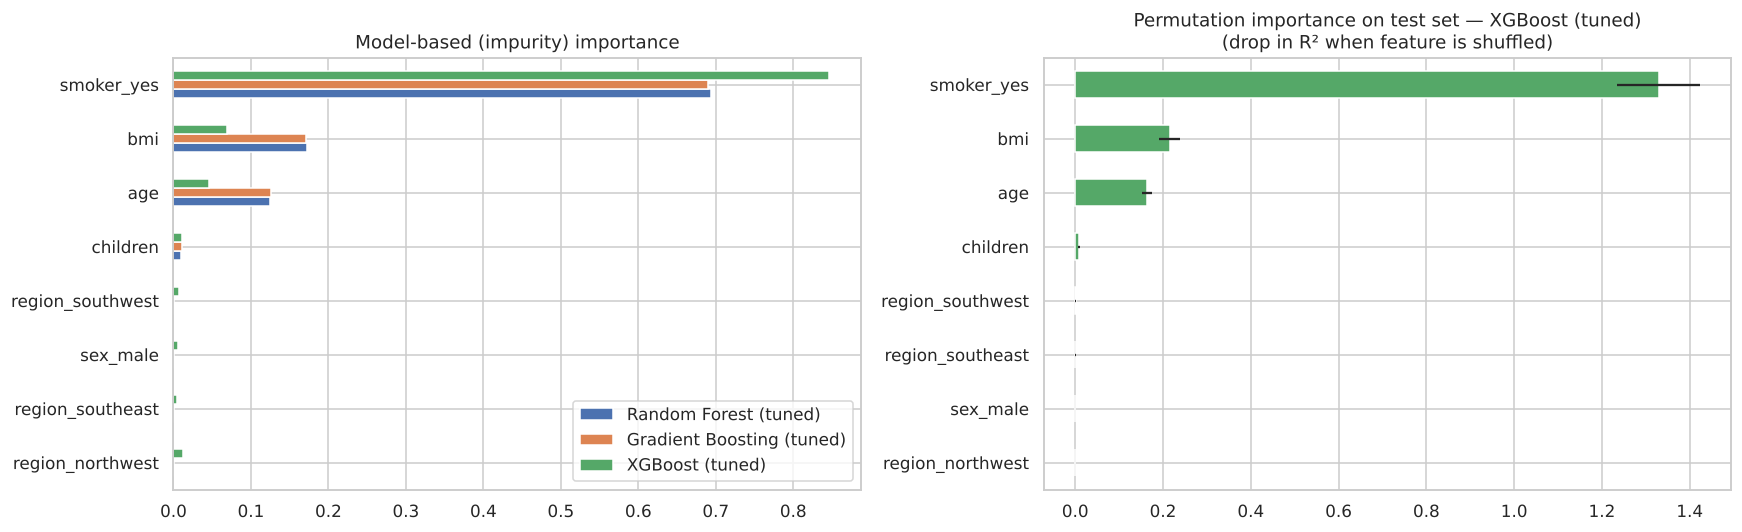

smoker_yes          1.329
bmi                 0.215
age                 0.164
children            0.009
region_southwest    0.001
region_southeast    0.001
sex_male           -0.000
region_northwest   -0.001
dtype: float64

In [29]:
def get_importances(model):
    est = model.steps[-1][1] if hasattr(model, 'steps') else model
    return pd.Series(est.feature_importances_, index=FEATURES)

imp = pd.DataFrame({n: get_importances(tuned[n]) for n in ['Random Forest (tuned)', 'Gradient Boosting (tuned)', 'XGBoost (tuned)']})
perm = permutation_importance(best_model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring='r2')
perm_s = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
RESULTS['impurity_importance'] = imp.round(4).to_dict()
RESULTS['perm_importance'] = perm_s.round(4).to_dict()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
imp.sort_values('Gradient Boosting (tuned)').plot.barh(ax=axes[0]); axes[0].set_title('Model-based (impurity) importance')
perm_s.plot.barh(ax=axes[1], color='#55A868', xerr=pd.Series(perm.importances_std, index=FEATURES)[perm_s.index])
axes[1].set_title(f'Permutation importance on test set — {best_name}\n(drop in R² when feature is shuffled)')
savefig('10_feature_importance')
perm_s.sort_values(ascending=False).round(3)

**Interpretation:** All three ensembles agree — **smoking status** dominates, followed by **BMI** and **age**.
Shuffling `smoker_yes` destroys most of the model's R²; BMI matters mainly *through its interaction with smoking*
(it splits smokers into ~$21k and ~$42k groups). `children`, `sex` and `region` contribute almost nothing.

### Extra check: can a linear model catch up with engineered interaction features?

In [30]:
def engineer(X):
    X = X.copy()
    X['obese'] = (X.bmi >= 30).astype(int)
    X['smoker_x_obese'] = X.smoker_yes * X.obese
    X['smoker_x_bmi'] = X.smoker_yes * X.bmi
    X['age_sq'] = X.age ** 2
    return X
Xtr_e, Xte_e = engineer(X_train), engineer(X_test)
lr_e = LinearRegression().fit(Xtr_e, y_train)
r = evaluate('Linear Regression + interactions', lr_e, Xtr_e, Xte_e)
RESULTS['lr_engineered'] = {k: (float(v) if k != 'Model' else v) for k, v in r.items()}
pd.Series(r)

Model       Linear Regression + interactions
Train R2                            0.865111
MAE                              2422.413457
RMSE                             4563.356426
R2                                  0.878305
dtype: object

Adding the domain-driven `smoker × obese` interaction and `age²` lifts Linear Regression to roughly the level of the
ensembles. This confirms the EDA finding: the core structure is *smoker × obesity* plus a convex age effect. The ensemble
learns this automatically; the linear model needs it hand-crafted.

# WEEK 4 — Interpretation, Documentation & Deployment Insight

In [31]:
summary = final_df[['MAE', 'RMSE', 'R2', 'CV R2 (5-fold)', 'Train R2']].copy()
summary['Overfit gap (Train R2 − Test R2)'] = summary['Train R2'] - summary['R2']
summary.style.format('{:.3f}', subset=['R2', 'CV R2 (5-fold)', 'Train R2', 'Overfit gap (Train R2 − Test R2)']).format('{:,.0f}', subset=['MAE', 'RMSE'])

,MAE,RMSE,R2,CV R2 (5-fold),Train R2,Overfit gap (Train R2 − Test R2)
Model,,,,,,
XGBoost (tuned),"2,566","4,622",0.875,0.846,0.881,0.005
Random Forest (tuned),"2,577","4,636",0.874,0.847,0.870,-0.004
Gradient Boosting (tuned),"2,625","4,698",0.871,0.845,0.870,-0.001
Decision Tree (tuned),"2,720","4,779",0.867,0.836,0.863,-0.004
KNN (default),"3,549","5,731",0.808,0.769,0.855,0.047
KNN (tuned),"3,424","5,743",0.807,0.775,1.000,0.193
Decision Tree (default),"2,885","6,204",0.775,0.682,1.000,0.225
Linear Regression,"4,182","6,240",0.772,0.723,0.736,-0.036


## Final model selection justification
**Selected model: tuned XGBoost** (`max_depth=3`, `learning_rate=0.03`, `n_estimators=200`, `colsample_bytree=0.8`).
1. **Accuracy** — lowest test RMSE (≈ $4,622) and MAE (≈ $2,566) and highest R² (≈ 0.875) of all required models.
2. **Stability** — 5-fold CV R² ≈ 0.846 on the training data is close to the test R², so the result is not luck of the split.
3. **Generalisation** — train R² ≈ 0.881 vs test ≈ 0.875: almost no overfitting, compared with the unpruned tree (1.00 vs 0.78).
4. **Interpretability** — feature importances agree with domain knowledge and EDA.

**Honest caveat:** tuned Random Forest, Gradient Boosting and even a depth-4 Decision Tree are within about $160 RMSE
of XGBoost, so the ensembles are effectively tied. Linear Regression *with hand-made interaction features* is
slightly better still on this split (R² ≈ 0.878). XGBoost is chosen because it reaches that level **without**
manual feature engineering and is robust if new interactions exist in new data; the engineered linear model is a
very good, fully transparent alternative if regulators require a simple formula.

## Business insights
- **Smoking is the single largest cost driver.** Smokers cost roughly 3.8× more on average. Smoking-cessation programmes
  and smoker loading in premiums are directly justified by the data.
- **Obesity sharply amplifies smoking risk.** Smokers with BMI ≥ 30 cost about twice as much as smokers with BMI < 30,
  while obesity alone adds little for non-smokers. The highest-value wellness target is the obese-smoker segment.
- **Age increases cost steadily** (a few hundred dollars per year of age), giving a predictable baseline curve.
- **Sex, region and number of children are weak predictors.** Pricing on them adds little accuracy and may raise fairness/regulatory concerns.

## Model limitations
- Only 1,338 records and 6 features; no medical history, pre-existing conditions, or claims history.
- Large positive residuals for some non-smokers — unpredictable high-cost events are not captured.
- Data is US-based (4 US regions); does not transfer directly to the Indian market without retraining.
- Point predictions only; no uncertainty interval for underwriting decisions.
- Sensitive attributes (sex, region) raise fairness questions for real-world pricing.

## Future improvements
- Add richer features (medical history, lifestyle, prior claims) and more data.
- Quantile regression / prediction intervals (e.g. quantile gradient boosting) for risk bands.
- SHAP values for per-customer explanations.
- Model the target on a log scale or with a Tweedie/Gamma loss suited to cost data.
- Fairness audit and monitoring for data drift after deployment.

### Save the final model for deployment

In [32]:
joblib.dump({'model': best_model, 'features': FEATURES, 'name': best_name}, 'insurance_model.joblib')
with open('results.json', 'w') as f:
    json.dump(RESULTS, f, indent=2, default=float)
print('Saved insurance_model.joblib and results.json')

Saved insurance_model.joblib and results.json


In [33]:
# Example prediction for a new customer
def predict_cost(age, sex, bmi, children, smoker, region):
    row = {f: 0 for f in FEATURES}
    row.update({'age': age, 'bmi': bmi, 'children': children,
                'sex_male': int(sex == 'male'), 'smoker_yes': int(smoker == 'yes')})
    if f'region_{region}' in row: row[f'region_{region}'] = 1
    return float(best_model.predict(pd.DataFrame([row])[FEATURES])[0])

examples = [(30, 'male', 25.0, 1, 'no', 'northeast'), (30, 'male', 25.0, 1, 'yes', 'northeast'),
            (30, 'male', 34.0, 1, 'yes', 'northeast'), (55, 'female', 34.0, 2, 'no', 'southeast')]
ex = pd.DataFrame(examples, columns=['age', 'sex', 'bmi', 'children', 'smoker', 'region'])
ex['predicted_charges'] = [round(predict_cost(*e)) for e in examples]
RESULTS['examples'] = ex.to_dict(orient='records')
with open('results.json', 'w') as f:
    json.dump(RESULTS, f, indent=2, default=float)
ex

,age,sex,bmi,children,smoker,region,predicted_charges
0,30,male,25.0,1,no,northeast,5276
1,30,male,25.0,1,yes,northeast,19262
2,30,male,34.0,1,yes,northeast,39183
3,55,female,34.0,2,no,southeast,14292


## Deployment insight
The saved `insurance_model.joblib` can be loaded by a small Streamlit or Flask app: the user enters age, sex, BMI,
children, smoker and region, and the app calls `predict_cost()` (above) to show the predicted annual charges.